In [49]:
import pandas as pd

# Load the dataset
data = pd.read_excel(r'C:\Users\shahu\OPEN CLASSROOMS\PROJET 3\outputs\data_modelisation.xlsx')
data.head()

,BuildingType,ZipCode,NumberofFloors,PropertyGFAParking,LargestPropertyUseType,LargestPropertyUseTypeGFA,SecondLargestPropertyUseType,SecondLargestPropertyUseTypeGFA,ThirdLargestPropertyUseType,ThirdLargestPropertyUseTypeGFA,ENERGYSTARScore,SiteEnergyUseWN(kBtu),TotalGHGEmissions,hasEnergyStarScore,Age,Ratio_LargestPropertyShare,Ratio_ElectricityShare,EnergyMix,isMixedProperty
0,NonResidential,98101,12,0,hotel,88434,NaN,0,NaN,0,60.000000,7456910,250,1,98,1.000000,0.529177,SEN,0
1,NonResidential,98101,11,15064,hotel,83880,parking,15064,restaurant,4622,61.000000,8664479,296,1,29,0.947775,0.374270,EN,1
2,NonResidential,98101,10,0,hotel,61320,NaN,0,NaN,0,56.000000,6946801,286,1,99,1.000000,0.398590,SEN,0
3,NonResidential,98121,18,62000,hotel,123445,parking,68009,NaN,0,75.000000,14656503,505,1,45,0.850914,0.366295,EN,0
4,Nonresidential COS,98101,2,37198,police station,88830,NaN,0,NaN,0,60.909091,12581712,302,0,26,0.850914,0.585885,EN,0


# MODELISATION (reduction of , Energy Consumption as a predictor of emissions)

In [50]:

# Step 2: Drop the column
data = data.drop(columns=["hasEnergyStarScore"])
data = data.drop(columns=["ENERGYSTARScore"])



## Removing features to reduce noise

In [51]:
cols_to_drop = [
    "ZipCode",
    "PropertyGFAparking",
    "ThirdLargestPropertyUseType",
    "EnergyMix",
    "SecondLargestPropertyUseType",
    "BuildingType",
    "isMixedProperty"
]

# Return a new DataFrame without those columns
data = data.drop(columns=cols_to_drop, errors="ignore")


In [52]:
pip install catboost

Note: you may need to restart the kernel to use updated packages.


In [53]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from catboost import CatBoostRegressor
from sklearn.dummy import DummyRegressor

models = {
    "Dummy": DummyRegressor(strategy="mean"),
    "LinearRegression": LinearRegression(),
    "Ridge": Ridge(alpha=1.0),
    "Lasso": Lasso(alpha=0.001, max_iter=50000),
    "RandomForest": RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1),
    "GradientBoosting": GradientBoostingRegressor(random_state=42),
    "CatBoost": CatBoostRegressor(verbose=0, random_state=42)
}


In [54]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_percentage_error
from sklearn.model_selection import train_test_split
from sklearn.base import clone
import numpy as np
import pandas as pd

# 1) Feature matrix excludes targets
features = [c for c in data.columns if c not in [energy_col, emissions_col]]
X = data[features]

# 2) Identify categorical and numeric columns based on X (not full data)
cat_cols = X.select_dtypes(include=["object", "category"]).columns.tolist()
num_cols_all = X.select_dtypes(exclude=["object", "category"]).columns.tolist()

# 3) Ensure categorical columns are string
for col in cat_cols:
    X[col] = X[col].astype(str)

# 4) Define numeric sets relative to X (targets are already excluded)
#    For energy model: you wanted to exclude energy and emissions, but they’re not in X anymore.
#    So just use num_cols_all.
num_cols_set1 = num_cols_all.copy()

#    For GHG model: keep energy as a predictor? Then energy must be included in X.
#    If you want energy as a predictor, rebuild X2 that includes energy_col.
use_energy_as_predictor_for_ghg = True

# Preprocessor for energy (no target cols in X)
preprocessor_set1 = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
    ("num", StandardScaler(), num_cols_set1),
])

# Build X2 for GHG if you want energy as predictor
if use_energy_as_predictor_for_ghg and energy_col in data.columns:
    features_g = [c for c in data.columns if c != emissions_col]  # keep energy, drop emissions
    X_g = data[features_g]
    # Types for X_g
    cat_cols_g = X_g.select_dtypes(include=["object", "category"]).columns.tolist()
    num_cols_g = X_g.select_dtypes(exclude=["object", "category"]).columns.tolist()
    for col in cat_cols_g:
        X_g[col] = X_g[col].astype(str)

    preprocessor_set2 = ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols_g),
        ("num", StandardScaler(), num_cols_g),
    ])
else:
    # Fall back to same X if not using energy as predictor (or energy missing)
    X_g = X.copy()
    cat_cols_g = cat_cols
    num_cols_g = num_cols_all
    preprocessor_set2 = ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols_g),
        ("num", StandardScaler(), num_cols_g),
    ])

# Targets
y_energy = data[energy_col]
y_ghg = data[emissions_col]

# Consistent split
train_idx, test_idx = train_test_split(data.index, test_size=0.2, random_state=42)

X_train = X.loc[train_idx]
X_test = X.loc[test_idx]
y_train_e = y_energy.loc[train_idx]
y_test_e = y_energy.loc[test_idx]

Xg_train = X_g.loc[train_idx]
Xg_test = X_g.loc[test_idx]
y_train_g = y_ghg.loc[train_idx]
y_test_g = y_ghg.loc[test_idx]

# Sanity checks: ensure all preprocessor columns exist in X and X_g
assert set(cat_cols).issubset(X_train.columns), "cat_cols not subset of X"
assert set(num_cols_all).issubset(X_train.columns), "num_cols not subset of X"
assert set(cat_cols_g).issubset(Xg_train.columns), "cat_cols_g not subset of X_g"
assert set(num_cols_g).issubset(Xg_train.columns), "num_cols_g not subset of X_g"

# Train/evaluate
results = []
for name, model in models.items():
    # Energy
    pipe_e = Pipeline(steps=[("preprocessor", preprocessor_set1), ("model", clone(model))])
    pipe_e.fit(X_train, y_train_e)
    y_pred_e = pipe_e.predict(X_test)
    r2_e = r2_score(y_test_e, y_pred_e)
    rmse_e = np.sqrt(mean_squared_error(y_test_e, y_pred_e))
    mape_e = mean_absolute_percentage_error(y_test_e, y_pred_e)

    # GHG
    pipe_g = Pipeline(steps=[("preprocessor", preprocessor_set2), ("model", clone(model))])
    pipe_g.fit(Xg_train, y_train_g)
    y_pred_g = pipe_g.predict(Xg_test)
    r2_g = r2_score(y_test_g, y_pred_g)
    rmse_g = np.sqrt(mean_squared_error(y_test_g, y_pred_g))
    mape_g = mean_absolute_percentage_error(y_test_g, y_pred_g)

    results.append({
        "Model": name,
        "R2_Energy": r2_e,
        "RMSE_Energy": rmse_e,
        "MAPE_Energy": mape_e,
        "R2_GHG": r2_g,
        "RMSE_GHG": rmse_g,
        "MAPE_GHG": mape_g
    })

results_df = pd.DataFrame(results).sort_values(by="R2_Energy", ascending=False)
print(results_df)


C:\Users\shahu\AppData\Local\Temp\ipykernel_1504\3562145736.py:20: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X[col] = X[col].astype(str)
C:\Users\shahu\AppData\Local\Temp\ipykernel_1504\3562145736.py:45: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X_g[col] = X_g[col].astype(str)


c:\Users\shahu\anaconda3\envs\env\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.521e+15, tolerance: 9.519e+12
  model = cd_fast.enet_coordinate_descent(


              Model  R2_Energy   RMSE_Energy  MAPE_Energy    R2_GHG  \
5  GradientBoosting   0.778437  3.724369e+06     0.965962  0.934215   
4      RandomForest   0.777878  3.729058e+06     0.884508  0.964244   
6          CatBoost   0.776977  3.736616e+06     0.818623  0.964662   
2             Ridge   0.704113  4.303948e+06     1.275258  0.813767   
3             Lasso   0.676973  4.497006e+06     1.299927  0.788837   
1  LinearRegression   0.675229  4.509126e+06     1.308806  0.788516   
0             Dummy  -0.000289  7.913464e+06     3.758272 -0.000904   

     RMSE_GHG  MAPE_GHG  
5   45.237367  0.299543  
4   33.350865  0.115417  
6   33.155641  0.223607  
2   76.113560  2.504857  
3   81.047998  2.550658  
1   81.109627  2.555636  
0  176.453397  7.493740  


In [55]:
from sklearn.model_selection import cross_val_score, KFold
from sklearn.metrics import make_scorer, r2_score, mean_squared_error, mean_absolute_percentage_error
from sklearn.pipeline import Pipeline
from sklearn.base import clone
import numpy as np
import pandas as pd

# Custom RMSE scorer
def rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

# 1) Cross-validation setup
cv = KFold(n_splits=5, shuffle=True, random_state=42)

# 2) Scorers
scoring = {
    "r2": make_scorer(r2_score),
    "rmse": make_scorer(rmse, greater_is_better=False),
    "mape": make_scorer(mean_absolute_percentage_error, greater_is_better=False),
}

# 3) Run CV on training data
cv_results = []

for name, model in models.items():
    # Energy: use preprocessor_set1 and X_train / y_train_e
    pipe_e = Pipeline(steps=[("preprocessor", preprocessor_set1), ("model", clone(model))])
    # R2
    scores_e_r2 = cross_val_score(pipe_e, X_train, y_train_e, cv=cv, scoring=scoring["r2"])
    # RMSE and MAPE (note: stored as negative because greater_is_better=False)
    scores_e_rmse = cross_val_score(pipe_e, X_train, y_train_e, cv=cv, scoring=scoring["rmse"])
    scores_e_mape = cross_val_score(pipe_e, X_train, y_train_e, cv=cv, scoring=scoring["mape"])

    # GHG: use preprocessor_set2 and Xg_train / y_train_g
    pipe_g = Pipeline(steps=[("preprocessor", preprocessor_set2), ("model", clone(model))])
    scores_g_r2 = cross_val_score(pipe_g, Xg_train, y_train_g, cv=cv, scoring=scoring["r2"])
    scores_g_rmse = cross_val_score(pipe_g, Xg_train, y_train_g, cv=cv, scoring=scoring["rmse"])
    scores_g_mape = cross_val_score(pipe_g, Xg_train, y_train_g, cv=cv, scoring=scoring["mape"])

    cv_results.append({
        "Model": name,
        "R2_Energy_Mean": np.mean(scores_e_r2),
        "R2_Energy_SD": np.std(scores_e_r2),
        "RMSE_Energy_Mean": -np.mean(scores_e_rmse),  # flip sign back
        "RMSE_Energy_SD": np.std(scores_e_rmse),
        "MAPE_Energy_Mean": -np.mean(scores_e_mape),
        "MAPE_Energy_SD": np.std(scores_e_mape),
        "R2_GHG_Mean": np.mean(scores_g_r2),
        "R2_GHG_SD": np.std(scores_g_r2),
        "RMSE_GHG_Mean": -np.mean(scores_g_rmse),
        "RMSE_GHG_SD": np.std(scores_g_rmse),
        "MAPE_GHG_Mean": -np.mean(scores_g_mape),
        "MAPE_GHG_SD": np.std(scores_g_mape),
    })

cv_results_df = pd.DataFrame(cv_results).sort_values(by="R2_Energy_Mean", ascending=False)
print("✅ Cross-Validation Results (5-fold on Training Data):\n")
display(cv_results_df)

# 4) Final evaluation on test set
test_results = []

for name, model in models.items():
    # Energy: fit on full training data (X_train -> y_train_e)
    pipe_e = Pipeline(steps=[("preprocessor", preprocessor_set1), ("model", clone(model))])
    pipe_e.fit(X_train, y_train_e)
    y_pred_e = pipe_e.predict(X_test)
    r2_e_test = r2_score(y_test_e, y_pred_e)
    rmse_e_test = rmse(y_test_e, y_pred_e)
    mape_e_test = mean_absolute_percentage_error(y_test_e, y_pred_e)

    # GHG: fit on full training data (Xg_train -> y_train_g)
    pipe_g = Pipeline(steps=[("preprocessor", preprocessor_set2), ("model", clone(model))])
    pipe_g.fit(Xg_train, y_train_g)
    y_pred_g = pipe_g.predict(Xg_test)
    r2_g_test = r2_score(y_test_g, y_pred_g)
    rmse_g_test = rmse(y_test_g, y_pred_g)
    mape_g_test = mean_absolute_percentage_error(y_test_g, y_pred_g)

    test_results.append({
        "Model": name,
        "R2_Energy_Test": r2_e_test,
        "RMSE_Energy_Test": rmse_e_test,
        "MAPE_Energy_Test": mape_e_test,
        "R2_GHG_Test": r2_g_test,
        "RMSE_GHG_Test": rmse_g_test,
        "MAPE_GHG_Test": mape_g_test,
    })

test_results_df = pd.DataFrame(test_results).sort_values(by="R2_Energy_Test", ascending=False)
print("\n" + "="*80)
print("📊 FINAL TEST SET EVALUATION")
print("="*80 + "\n")
print("Test Set Results:\n")
display(test_results_df)


c:\Users\shahu\anaconda3\envs\env\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.634e+15, tolerance: 7.617e+12
  model = cd_fast.enet_coordinate_descent(
c:\Users\shahu\anaconda3\envs\env\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.995e+14, tolerance: 7.130e+12
  model = cd_fast.enet_coordinate_descent(
c:\Users\shahu\anaconda3\envs\env\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duali

✅ Cross-Validation Results (5-fold on Training Data):



,Model,R2_Energy_Mean,R2_Energy_SD,RMSE_Energy_Mean,RMSE_Energy_SD,MAPE_Energy_Mean,MAPE_Energy_SD,R2_GHG_Mean,R2_GHG_SD,RMSE_GHG_Mean,RMSE_GHG_SD,MAPE_GHG_Mean,MAPE_GHG_SD
6,CatBoost,0.692873,0.025175,4.751373e+06,341667.348900,0.726322,0.129974,0.826784,0.079009,81.588252,24.163441,1.119974e+13,2.239949e+13
5,GradientBoosting,0.673396,0.022605,4.903195e+06,370336.811178,0.841412,0.159157,0.799068,0.066896,89.403723,21.927878,3.426535e+12,6.853071e+12
3,Lasso,0.663776,0.059734,4.967022e+06,653590.706348,1.062763,0.146227,0.725422,0.073996,103.984068,14.487381,1.562204e+14,3.124408e+14
1,LinearRegression,0.663288,0.061653,4.968785e+06,660044.679929,1.075888,0.151669,0.725473,0.073736,103.980629,14.448492,1.565260e+14,3.130520e+14
2,Ridge,0.659910,0.060637,4.991736e+06,637396.123663,1.057959,0.148480,0.747863,0.058588,100.121687,13.974884,1.467131e+14,2.934263e+14
4,RandomForest,0.643568,0.047413,5.105641e+06,374738.055898,0.782597,0.168907,0.811236,0.067820,86.586199,23.150989,3.975834e+12,7.951668e+12
0,Dummy,-0.004345,0.002318,8.614228e+06,718914.112734,3.068093,0.369420,-0.001986,0.002443,201.321293,22.235361,4.382696e+14,8.765393e+14


c:\Users\shahu\anaconda3\envs\env\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.521e+15, tolerance: 9.519e+12
  model = cd_fast.enet_coordinate_descent(



📊 FINAL TEST SET EVALUATION

Test Set Results:



,Model,R2_Energy_Test,RMSE_Energy_Test,MAPE_Energy_Test,R2_GHG_Test,RMSE_GHG_Test,MAPE_GHG_Test
5,GradientBoosting,0.778437,3.724369e+06,0.965962,0.934215,45.237367,0.299543
4,RandomForest,0.777878,3.729058e+06,0.884508,0.964244,33.350865,0.115417
6,CatBoost,0.776977,3.736616e+06,0.818623,0.964662,33.155641,0.223607
2,Ridge,0.704113,4.303948e+06,1.275258,0.813767,76.113560,2.504857
3,Lasso,0.676973,4.497006e+06,1.299927,0.788837,81.047998,2.550658
1,LinearRegression,0.675229,4.509126e+06,1.308806,0.788516,81.109627,2.555636
0,Dummy,-0.000289,7.913464e+06,3.758272,-0.000904,176.453397,7.493740


In [56]:
from sklearn.model_selection import RandomizedSearchCV, train_test_split, cross_val_score, KFold
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_percentage_error
import numpy as np
import pandas as pd

# Assumes these variables exist from prior steps:
# - data, energy_col, emissions_col
# - X (features without targets), X_g (features keeping energy for GHG if used)
# - preprocessor_set1 (for energy), preprocessor_set2 (for GHG)
# - (If you used different names, rename accordingly.)

# 1) TRAIN/TEST SPLIT (use the same indices for both targets)
train_idx, test_idx = train_test_split(data.index, test_size=0.2, random_state=42)
X_train = X.loc[train_idx]
X_test = X.loc[test_idx]

# If you have X_g (features for GHG that include energy)
try:
    Xg_train = X_g.loc[train_idx]
    Xg_test = X_g.loc[test_idx]
except NameError:
    # If X_g doesn't exist, fall back to X (GHG will not include energy as predictor)
    Xg_train = X_train.copy()
    Xg_test = X_test.copy()

y_train_e = data[energy_col].loc[train_idx]
y_test_e = data[energy_col].loc[test_idx]
y_train_g = data[emissions_col].loc[train_idx]
y_test_g = data[emissions_col].loc[test_idx]

# 2) Hyperparameter grid (same as you provided)
param_grid = {
    "model__n_estimators": [200, 400, 600],
    "model__max_depth": [10, 15, 20, None],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4],
    "model__max_features": ["sqrt", "log2", None, 0.5],
    "model__bootstrap": [True, False],
}

print("="*80)
print("STEP 1: HYPERPARAMETER TUNING - RandomizedSearchCV (200 Samples)")
print("="*80)

# 3) RandomizedSearchCV for ENERGY
print("\nTuning for ENERGY prediction (RandomizedSearchCV)...") # <-- Corrected this line
pipe_e = Pipeline([
    ("preprocessor", preprocessor_set1),
    ("model", RandomForestRegressor(random_state=42))
])

random_search_e = RandomizedSearchCV(
    pipe_e,
    param_grid,
    n_iter=200,
    cv=5,
    scoring="r2",
    n_jobs=-1,
    random_state=42,
    verbose=1
)

random_search_e.fit(X_train, y_train_e)

print("\nBest params for Energy:") # <-- Corrected this line (was split over two lines)
for key, value in random_search_e.best_params_.items():
    print(f"   {key}: {value}")
print(f"Best CV R² (Energy): {random_search_e.best_score_:.4f}")

# 4) RandomizedSearchCV for GHG
print("\nTuning for GHG prediction (RandomizedSearchCV)...") # <-- Corrected this line
pipe_g = Pipeline([
    ("preprocessor", preprocessor_set2),
    ("model", RandomForestRegressor(random_state=42))
])

random_search_g = RandomizedSearchCV(
    pipe_g,
    param_grid,
    n_iter=200,
    cv=5,
    scoring="r2",
    n_jobs=-1,
    random_state=42,
    verbose=1
)

random_search_g.fit(Xg_train, y_train_g)

print("\nBest params for GHG:") # <-- Corrected this line (was split over two lines)
for key, value in random_search_g.best_params_.items():
    print(f"   {key}: {value}")
print(f"Best CV R² (GHG): {random_search_g.best_score_:.4f}")

# 5) CROSS-VALIDATION CONFIRMATION on training folds
print("\n" + "="*80)
print("STEP 2: CROSS-VALIDATION CONFIRMATION (on Training Data)")
print("="*80)

best_model_e = random_search_e.best_estimator_
best_model_g = random_search_g.best_estimator_

cv = KFold(n_splits=5, shuffle=True, random_state=42)
cv_scores_e = cross_val_score(best_model_e, X_train, y_train_e, cv=cv, scoring="r2", n_jobs=-1)
cv_scores_g = cross_val_score(best_model_g, Xg_train, y_train_g, cv=cv, scoring="r2", n_jobs=-1)


STEP 1: HYPERPARAMETER TUNING - RandomizedSearchCV (200 Samples)

Tuning for ENERGY prediction (RandomizedSearchCV)...
Fitting 5 folds for each of 200 candidates, totalling 1000 fits

Best params for Energy:
   model__n_estimators: 600
   model__min_samples_split: 2
   model__min_samples_leaf: 1
   model__max_features: sqrt
   model__max_depth: None
   model__bootstrap: False
Best CV R² (Energy): 0.6684

Tuning for GHG prediction (RandomizedSearchCV)...
Fitting 5 folds for each of 200 candidates, totalling 1000 fits

Best params for GHG:
   model__n_estimators: 200
   model__min_samples_split: 10
   model__min_samples_leaf: 1
   model__max_features: None
   model__max_depth: 15
   model__bootstrap: True
Best CV R² (GHG): 0.8117

STEP 2: CROSS-VALIDATION CONFIRMATION (on Training Data)



FEATURE IMPORTANCES (Top 20) - ENERGY model
                                              Feature  Importance
0                      num__LargestPropertyUseTypeGFA    0.301426
1                num__SecondLargestPropertyUseTypeGFA    0.135324
2                                 num__NumberofFloors    0.112570
3                 num__ThirdLargestPropertyUseTypeGFA    0.069103
4                         num__Ratio_ElectricityShare    0.062195
5                             num__PropertyGFAParking    0.061563
6                                            num__Age    0.057577
7                     num__Ratio_LargestPropertyShare    0.045957
8              cat__LargestPropertyUseType_laboratory    0.020341
9   cat__LargestPropertyUseType_hospital (general ...    0.013772
10            cat__LargestPropertyUseType_data center    0.012188
11     cat__LargestPropertyUseType_college/university    0.011818
12  cat__LargestPropertyUseType_non-refrigerated w...    0.010794
13  cat__LargestPropertyUseType

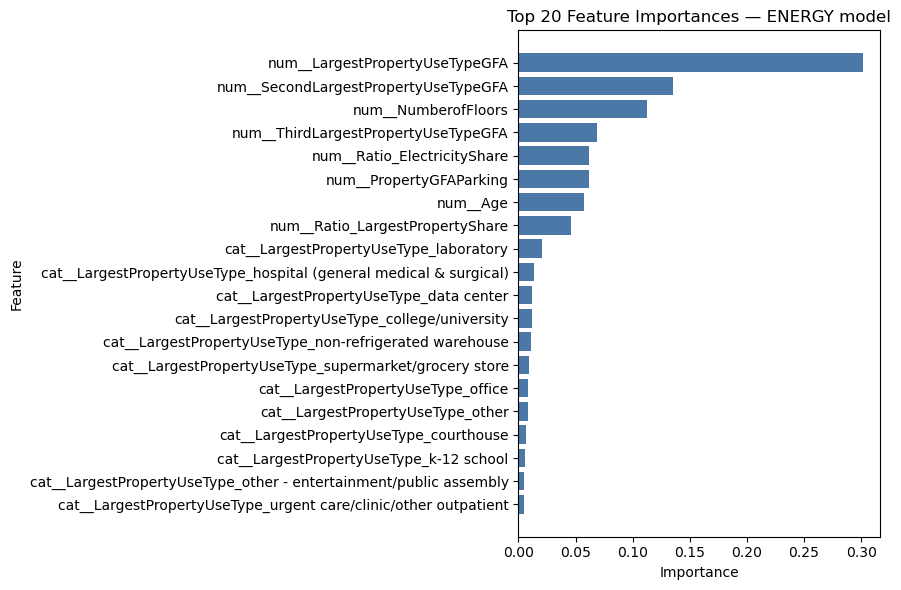

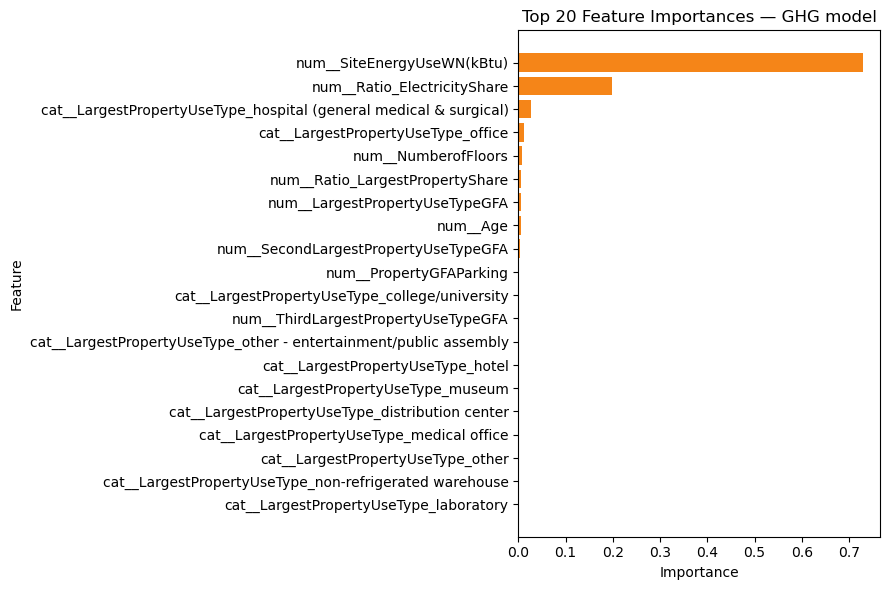

In [57]:
# Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer

# ---------- Helpers ----------

def get_pipeline_feature_names(pipeline, X):
    """
    Return feature names after the pipeline's preprocessing step.
    - Supports ColumnTransformer and transformers with get_feature_names_out.
    - Falls back to numeric names based on transformed shape.
    """
    pre = None
    if hasattr(pipeline, "named_steps"):
        pre = pipeline.named_steps.get("preprocessor", None)

    if pre is None:
        if hasattr(X, "columns"):
            return list(X.columns)
        return [f"feature_{i}" for i in range(X.shape[1])]

    # Try standard API on the preprocessor
    try:
        if hasattr(pre, "get_feature_names_out"):
            names = pre.get_feature_names_out()
            return list(names)
    except Exception:
        pass

    # Handle ColumnTransformer with sub-transformers
    if isinstance(pre, ColumnTransformer):
        out_names = []
        for name, transformer, cols in pre.transformers_:
            if name == 'remainder' and transformer == 'drop':
                continue
            if transformer == 'drop':
                continue
            if transformer == 'passthrough':
                if hasattr(cols, "__iter__"):
                    if hasattr(X, "columns"):
                        try:
                            out_names.extend(list(X.columns[cols] if hasattr(cols, "dtype") else cols))
                        except Exception:
                            out_names.extend(list(cols))
                    else:
                        out_names.extend(list(cols))
                else:
                    out_names.append(str(cols))
                continue
            # Transformer names
            try:
                if hasattr(transformer, "get_feature_names_out"):
                    base = transformer.get_feature_names_out(cols if hasattr(cols, "__iter__") else [cols])
                    out_names.extend(list(base))
                    continue
            except Exception:
                pass
            # Fallback: infer output width
            try:
                X_part = X[cols] if hasattr(X, "loc") else X[:, cols]
                try:
                    Xt_part = transformer.transform(X_part)
                except Exception:
                    transformer = transformer.fit(X_part)
                    Xt_part = transformer.transform(X_part)
            except Exception:
                Xt_part = None
            if Xt_part is not None:
                n_out = Xt_part.shape[1] if len(getattr(Xt_part, "shape", [])) == 2 else 1
                base_cols = cols if hasattr(cols, "__iter__") else [cols]
                base_cols = list(base_cols)
                if len(base_cols) == 1 and n_out > 1:
                    out_names.extend([f"{name}__{base_cols[0]}_{i}" for i in range(n_out)])
                else:
                    for i in range(n_out):
                        out_names.append(f"{name}__{i}")
            else:
                if hasattr(cols, "__iter__"):
                    out_names.extend([f"{name}__{c}" for c in cols])
                else:
                    out_names.append(f"{name}__{cols}")
        if out_names:
            return out_names

    # Last resort
    try:
        Xt = pre.transform(X)
    except Exception:
        pre = pre.fit(X)
        Xt = pre.transform(X)
    n_out = Xt.shape[1]
    return [f"feature_{i}" for i in range(n_out)]


def extract_importances(pipeline):
    """
    Get final step name and feature_importances_ if available.
    """
    if not hasattr(pipeline, "named_steps"):
        return None, None
    final_step_name = list(pipeline.named_steps.keys())[-1]
    final_est = pipeline.named_steps[final_step_name]
    importances = getattr(final_est, "feature_importances_", None)
    return final_step_name, importances


def top_features_sorted(names, imps, top_n=20):
    """
    Build a DataFrame of top-N features sorted by importance descending.
    """
    if imps is None or len(imps) == 0:
        return pd.DataFrame({"Feature": [], "Importance": []})
    if len(names) != len(imps):
        raise ValueError(f"Length mismatch: names={len(names)} vs importances={len(imps)}")
    df = pd.DataFrame({"Feature": names, "Importance": imps})
    df = df.sort_values("Importance", ascending=False).reset_index(drop=True)
    return df.head(top_n)


def plot_top_importances(df, title, figsize=(9, 6), color="#4C78A8"):
    """
    Plot a horizontal bar chart for a sorted top-N importance DataFrame.
    Expects columns: 'Feature', 'Importance' sorted desc already.
    """
    if df is None or df.empty:
        print(f"No importances to plot for: {title}")
        return
    df_plot = df.iloc[::-1]
    plt.figure(figsize=figsize)
    plt.barh(df_plot["Feature"], df_plot["Importance"], color=color)
    plt.title(title)
    plt.xlabel("Importance")
    plt.ylabel("Feature")
    plt.tight_layout()
    plt.show()


# ---------- Fit best pipelines, extract names/importances, sort, and plot ----------

# Assumes random_search_e and random_search_g are fitted RandomizedSearchCV objects
# and that X_train/X_test are for Energy; Xg_train/Xg_test are for GHG
best_e = random_search_e.best_estimator_
best_g = random_search_g.best_estimator_

# Fit on correct training data for each target
best_e.fit(X_train, y_train_e)    # Energy uses preprocessor_set1 and X_train
best_g.fit(Xg_train, y_train_g)   # GHG uses preprocessor_set2 and Xg_train

# Get transformed feature names per pipeline using the matching X
feature_names_e = get_pipeline_feature_names(best_e, X_train)
feature_names_g = get_pipeline_feature_names(best_g, Xg_train)

# Extract final step and importances
final_step_name_e, importances_e = extract_importances(best_e)
final_step_name_g, importances_g = extract_importances(best_g)

# Build sorted top-N DataFrames
top_n = 20
top_e = top_features_sorted(feature_names_e, importances_e, top_n=top_n)
top_g = top_features_sorted(feature_names_g, importances_g, top_n=top_n)

# Display DataFrames
print("\nFEATURE IMPORTANCES (Top 20) - ENERGY model")
print(top_e)

print("\nFEATURE IMPORTANCES (Top 20) - GHG model")
print(top_g)

# Plot horizontal bar charts (sorted)
plot_top_importances(top_e, title="Top 20 Feature Importances — ENERGY model", color="#4C78A8")
plot_top_importances(top_g, title="Top 20 Feature Importances — GHG model", color="#F58518")
